In [89]:
#julia -t 4

using Plots
using Random, Statistics, Distributions
using SparseArrays
using LinearAlgebra
using DifferentialEquations
using StatsPlots 

using Statistics 
using Distributions, Random, Plots, StatsBase  
using Base.Threads



include("../GPs.jl")


log_marginal_extended_exact (generic function with 1 method)

Maximum error = 0.017967945984084962
L2 error       = 0.042245174653731433


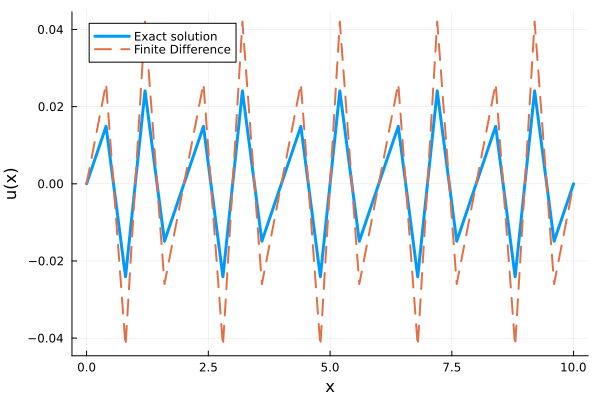

In [186]:
using LinearAlgebra
using Plots

# -----------------------------
# Problem setting
# -----------------------------

dt = 0.4
T = 10.0
x = 0:dt:T


xi = x[2:end-1]
n = length(xi)

# -----------------------------
# Construct finite difference matrix
# u'' =  - sin(2πx)
# -----------------------------
A = zeros(n, n)

for i in 1:n
    A[i,i] = - 2.0
    if i > 1
        A[i,i-1] =  1.0
    end
    if i < n
        A[i,i+1] = 1.0
    end
end

A ./= (dt)^2

# Right-hand side
f =  - sin.(2π .* xi)

# Solve linear system
u_interior = A \ f

# Include boundary values
u_num = vcat(0.0, u_interior, 0.0)

# -----------------------------
# Exact solution
# -----------------------------
u_exact_vec = (1/(2π)^2) .* sin.(2π .* x)

# -----------------------------
# Error
# -----------------------------
max_error = maximum(abs.(u_num .- u_exact_vec))
l2_error = sqrt(sum((u_num .- u_exact_vec).^2) * (dt))

println("Maximum error = ", max_error)
println("L2 error       = ", l2_error)

# -----------------------------
# Plot
# -----------------------------
plot(x, u_exact_vec,
    lw=3,
    label="Exact solution",
    xlabel="x",
    ylabel="u(x)")

plot!(x, u_num,
    linestyle=:dash,
    lw=2,
    label="Finite Difference")

In [187]:




X_train = collect(0:dt:T)
y_train = -sin.(2π .* X_train)



println("X_train:", X_train)
println("y_train:", y_train)

println(y_train.size)

 
#

X_train:[0.0, 0.4, 0.8, 1.2, 1.6, 2.0, 2.4, 2.8, 3.2, 3.6, 4.0, 4.4, 4.8, 5.2, 5.6, 6.0, 6.4, 6.8, 7.2, 7.6, 8.0, 8.4, 8.8, 9.2, 9.6, 10.0]
y_train:[-0.0, -0.5877852522924732, 0.9510565162951536, -0.9510565162951535, 0.5877852522924728, 4.898587196589413e-16, -0.5877852522924736, 0.9510565162951538, -0.9510565162951533, 0.5877852522924725, 9.797174393178826e-16, -0.5877852522924711, 0.951056516295154, -0.9510565162951532, 0.587785252292472, 1.4695761589768238e-15, -0.5877852522924744, 0.9510565162951541, -0.951056516295153, 0.5877852522924716, 1.959434878635765e-15, -0.5877852522924748, 0.9510565162951521, -0.9510565162951506, 0.5877852522924712, 2.4492935982947065e-15]
(26,)


In [201]:
#ℓ = best_ℓ
ℓ = 0.1
σf = 0.1
C = 0.0001

l=1.0e-19
σf=0.03
C=0.001


# -------------------------
# Test Points
# -------------------------
#X_test = collect(range(-5, 5, length=300))

X_test = collect(range(0, T, length=300))
# -------------------------
# Covariance Matrices
# -------------------------



function laplacian_matrix(n, dt)

    # n = number of grid points (including boundary)
    D = zeros(n-2, n)

    #for i in 1:n-2
    #    D[i,i+1] = 1
    #end

    for i in 1:n-2
        D[i,i]   = 1
        D[i,i+1] = - 2
        D[i,i+2] = 1
    end

    return D ./ dt^2
end




function observation_matrix(n, dt)

    D = laplacian_matrix(n, dt)

    H = zeros(n, n)

    # u(0)
    H[1,1] = 1.0

    # Lu (internal)
    H[2:n-1, :] .= D

    # u(1)
    H[end,end] = 1.0

    return H
end

H = observation_matrix(length(X_train), dt)

println("H:", H)
println("H.size:", H.size)



#K =
#    kernel_matrix(X_train, X_train;
#                  ℓ=ℓ, σf=σf) +
#    σn^2 * I

K =
    H * kernel_matrix(X_train, X_train;
                  ℓ=ℓ, σf=σf) * H' +
#    σn^2 * I
     C * (dt)^4 * I


println("H * kernel_matrix(X_train, X_train;
                  ℓ=ℓ, σf=σf) * H':", H * kernel_matrix(X_train, X_train;
                  ℓ=ℓ, σf=σf) * H')

#K =
#    kernel_matrix(X_train, X_train;
#                  ℓ=ℓ, σf=σf)  +
#    σn^2 * I

println("K.size:", K.size)

Ks =
    kernel_matrix(X_train, X_test;
                  ℓ=ℓ, σf=σf)

println("Ks.size:", Ks.size)

Ks = H * Ks

Kss =
    kernel_matrix(X_test, X_test;
                  ℓ=ℓ, σf=σf)

println("Kss.size:", Kss.size)

# -------------------------
# Posterior Mean
# -------------------------
μ =
    transpose(Ks) *
    (K \ y_train)

# -------------------------
# Posterior Covariance
# -------------------------
Σ =
    Kss -
    transpose(Ks) *
    (K \ Ks)

std =
    sqrt.(diag(Σ))

#

H:[1.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0; 6.249999999999999 -12.499999999999998 6.249999999999999 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0; 0.0 6.249999999999999 -12.499999999999998 6.249999999999999 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0; 0.0 0.0 6.249999999999999 -12.499999999999998 6.249999999999999 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0; 0.0 0.0 0.0 6.249999999999999 -12.499999999999998 6.249999999999999 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0; 0.0 0.0 0.0 0.0 6.249999999999999 -12.499999999999998 6.249999999999999 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0; 0.0 0.0 0.0 0.0 0.0 6.249999999999999 -12.499999999999998 6.249999999999999 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0

300-element Vector{Float64}:
 0.0047434262732823345
 0.010742241445184084
 0.01841577928093258
 0.024072795511061822
 0.027444235474509655
 0.029038036707325826
 0.029470991582915912
 0.028997487514100133
 0.02734047234475914
 0.023873311304181848
 ⋮
 0.027340472344759177
 0.02899748751410016
 0.029470991582915912
 0.029038036707325836
 0.027444235474509648
 0.024072795511061753
 0.018415779280932746
 0.010742241445184195
 0.004743426273282312

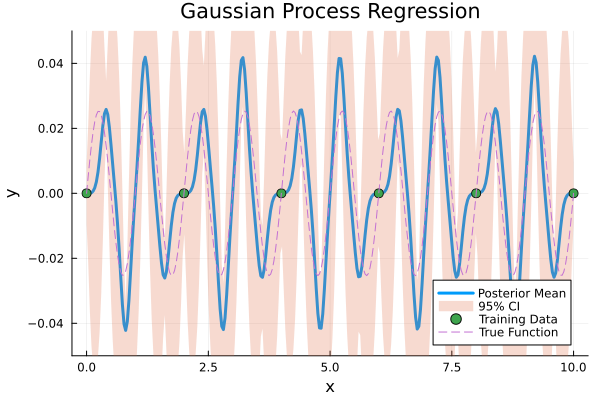

In [202]:
#-------------------------
# Visualization
# -------------------------
plot(
    X_test,
    μ,
    label="Posterior Mean",
    lw=3
)

plot!(
    X_test,
    μ .+ 1.96 .* std,
    fillrange=μ .- 1.96 .* std,
    fillalpha=0.25,
    linealpha=0,
    label="95% CI"
)

scatter!(
    X_train,
    y_train,
    label="Training Data",
    ms=5
)

plot!(
    X_test,
    #sin.(X_test),
    (1/(2π)^2) * sin.(2π .* X_test),
    ylims = (-0.05, 0.05),
    ls=:dash,
    label="True Function"
)

xlabel!("x")
ylabel!("y")
title!("Gaussian Process Regression")

In [190]:
function log_marginal_H(
    X_train,
    y;
    H,
    dt,
    ℓ,
    σf,
    prior_mean = 0.0
)

    K =
        H *
        kernel_matrix(X_train, X_train;
                      ℓ=ℓ,
                      σf=σf) *
        H' +
        C * (dt)^4 * I

    m = fill(prior_mean, length(y))

    L = cholesky(Hermitian(K)).L

    α = L' \ (L \ (y - m))

    logdetK = 2sum(log.(diag(L)))

    return -0.5 * (y - m)' * α -
           0.5 * logdetK -
           0.5 * length(y) * log(2π)
end

log_marginal_H (generic function with 1 method)

In [191]:
ℓ_grid = [0.001,0.1,0.5,1.0,2.0,5.0,10.0,100.0, 1000]

σf_grid = [0.0001,0.001,0.01,0.03,
           0.1,0.3,1.0,3.0,
           10.0,30.0,100.0,500.0, 1000.0, 10000.0]

scores = zeros(length(ℓ_grid), length(σf_grid))

for (i,ℓ) in enumerate(ℓ_grid)
    for (j,σf) in enumerate(σf_grid)

        scores[i,j] =
            log_marginal_H(
                X_train,
                y_train;
                H = H,
                dt = dt,
                ℓ = ℓ,
                σf = σf,
                prior_mean = 0.0
            )

    end
end

best_linear_idx = argmax(scores)

best_i, best_j =
    Tuple(CartesianIndices(scores)[best_linear_idx])

best_ℓ = ℓ_grid[best_i]
best_σf = σf_grid[best_j]

println(best_ℓ)
println(best_σf)

PosDefException: PosDefException: matrix is not positive definite; Factorization failed.

In [192]:
println()
println("================ GRID TABLE ================")

# header
print(rpad("σf \\ ℓ", 10))
for ℓ in ℓ_grid
    print(rpad(string(ℓ), 12))
end
println()

# body
for (j, σf) in enumerate(σf_grid)
    print(rpad(string(σf), 10))
    for (i, ℓ) in enumerate(ℓ_grid)
        print(rpad(round(scores[i,j], digits=4), 12))
    end
    println()
end


================ GRID TABLE ================
σf \ ℓ    0.001       0.1         0.5         1.0         2.0         5.0         10.0        100.0       1000.0      
0.0001    -974595.1449-975023.7667-4.4748307657e6-4.8819736386e6-4.8826275305e60.0         0.0         0.0         0.0         
0.001     -12072.5089 -12079.1313 -494969.3287-4.8502150546e6-4.8805146012e60.0         0.0         0.0         0.0         
0.01      -74.1246    -74.1907    -5497.7679  -4.4735442422e6-4.8532339522e60.0         0.0         0.0         0.0         
0.03      6.4104      6.4031      -581.9598   -3.8522643069e6-4.8143991501e60.0         0.0         0.0         0.0         
0.1       -12.4565    -12.4572    -50.0808    -2.561131294e6-4.743396055e60.0         0.0         0.0         0.0         
0.3       -39.9267    -39.9267    -29.1268    -1.3319726876e6-4.6303226986e60.0         0.0         0.0         0.0         
1.0       -71.1055    -71.1055    -54.7973    -372420.2185-4.4819429607e60.0        

In [193]:
function log_marginal_H(
    X_train,
    y;
    H,
    dt,
    ℓ,
    σf,
    C,
    prior_mean = 0.0
)

    K =
        H *
        kernel_matrix(X_train, X_train;
                      ℓ=ℓ,
                      σf=σf) *
        H' +
        C * (dt)^4 * I

    m = fill(prior_mean, length(y))

    L = cholesky(Hermitian(K)).L
    α = L' \ (L \ (y - m))

    logdetK = 2sum(log.(diag(L)))

    return -0.5 * ((y - m)' * α) -
           0.5 * logdetK -
           0.5 * length(y) * log(2π)
end

log_marginal_H (generic function with 1 method)

In [204]:
ℓ_grid = [ 0.0000000000000000001, 0.0001, 0.001,0.1,0.5,1.0,2.0,5.0,10.0,100.0, 1000]

σf_grid = [0.0001,0.001,0.01,0.03,
           0.1,0.3,1.0,3.0,
           10.0,30.0,100.0,500.0, 1000.0, 10000.0]

C_grid = [0.001,0.01,0.1 ,1,10,100, 1000]

scores = zeros(length(ℓ_grid),
               length(σf_grid),
               length(C_grid))

for (i,ℓ) in enumerate(ℓ_grid)
    for (j,σf) in enumerate(σf_grid)
        for (k,C) in enumerate(C_grid)

            scores[i,j,k] =
                log_marginal_H(
                    X_train,
                    y_train;
                    H=H,
                    dt=dt,
                    ℓ=ℓ,
                    σf=σf,
                    C=C,
                    prior_mean=0.0
                )

        end
    end
end

best_linear_idx = argmax(scores)
best_I = CartesianIndices(scores)[best_linear_idx]

best_ℓ  = ℓ_grid[best_I[1]]
best_σf = σf_grid[best_I[2]]
best_C  = C_grid[best_I[3]]
println("l=", best_ℓ)
println("σf=", best_σf)
println("C=", best_C)
best_loglik =
    log_marginal_H(
        X_train,
        y_train;
        H=H,
        dt=dt,
        ℓ=best_ℓ,
        σf=best_σf,
        C=best_C,
        prior_mean=0.0
    )

println("log marginal likelihood (best) = ", best_loglik)



l=1.0e-19
σf=0.03
C=0.001
log marginal likelihood (best) = 5.570506873863199
